# Student Placement Outcomes — A Reporting Notebook

## Project snapshot

| | |
|---|---|
| **Question** | What is the placement rate, what is the package among students who were placed, and which cuts actually change those two figures? |
| **Data** | Kaggle's [Student Placement Prediction Dataset 2026](https://www.kaggle.com/datasets/sehaj1104/student-placement-prediction-dataset-2026): 100,000 rows and 26 columns. The publisher describes the file as synthetic. |
| **Method** | Validate the file, write down the cleaning rule, run the report cuts in SQL, present KPI tables and a pivot, and draw only the comparisons those tables support. |
| **Result** | 54.5% are placed. Among placed students the mean package is 13.32 LPA and the median is 13.30 LPA. One-way branch rates sit between 54.1% and 55.2%. |

The file is a worked example of a reporting pass. It is not a hiring study and it is not a pay model.

## Skills this notebook shows

| Skill | Where it is shown |
|---|---|
| Data validation and data quality | Section 1. Counts, duplicate keys, missing values, range rules, and a status-against-amount check. |
| Cleaning with a written rule | Section 2. The identifier is removed only after the uniqueness check. Structural zeros are kept. |
| Field definitions | Section 2. A short dictionary of the fields that enter the report. |
| SQL: `GROUP BY`, `CASE`, window functions | Sections 1 and 3. The queries run in `sqlite3` against the table. |
| Excel-style summarising | Section 4. A branch-by-tier pivot with the counts beside the rates. |
| KPI reporting | Section 4. Placement rate and median package, each with its denominator. |
| Charts | Section 5. Three figures, labelled, on scales that do not inflate a small gap. |
| A light association check | Section 6. Pearson correlations for pay among placed students. No model is fit. |

Python is the language the notebook runs in. The SQL uses the standard-library `sqlite3` module, in memory, so the cuts can be read and re-run. The pivot is the table an analyst would build with an Excel PivotTable. Nothing is exported.


In [1]:
from IPython import get_ipython

_ipython = get_ipython()
if _ipython is not None:
    _ipython.run_line_magic("matplotlib", "inline")

import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import kagglehub

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "portfolio_utils").is_dir():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the repository root containing portfolio_utils")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from portfolio_utils import DATASETS_DIR

# Fixed even though these steps do not draw a sample. Later cells stay reproducible.
SEED = 42
np.random.seed(SEED)

BLUE = "#1F4E79"
INK = "#1C2830"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.color": "#E6ECF0",
    "grid.linewidth": 0.6,
})

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 140)

print(f"Repository root: {REPO_ROOT}")
print(f"Tracked dataset snapshots live in {DATASETS_DIR}. This file is downloaded, not tracked.")
print("pandas", pd.__version__, "| sqlite", sqlite3.sqlite_version)


Repository root: /workspace
Tracked dataset snapshots live in /workspace/datasets. This file is downloaded, not tracked.
pandas 3.1.1 | sqlite 3.45.1


## 1. Load the file and check it before quoting a rate

A placement rate is a count divided by a count. A package is an amount attached to a status. If the status and the amount disagree, or if the same student appears twice, every later table repeats the error. The checks below are fixed before the pass/fail result is counted.

The bounds are the documented CGPA scale (4.5 to 10), 0 to 100 for scores and attendance, 0 to 24 hours for sleep and study, 15 to 30 as a wide age screen, and zero or above for counts and salary. A salary of zero is inside that last rule. It is checked again, separately, against placement status. Categorical fields must be non-empty text. The same reconciliation is then repeated as a SQL query, so the rule is not only a Python expression.


In [2]:
dataset_dir = Path(kagglehub.dataset_download("sehaj1104/student-placement-prediction-dataset-2026"))
source_path = dataset_dir / "student_placement_prediction_dataset_2026.csv"
raw = pd.read_csv(source_path)

print(f"Rows: {len(raw):,}")
print(f"Columns: {raw.shape[1]}")
display(raw.head(3))

RANGE_RULES = {
    "age": (15, 30, "15 to 30, a wide age screen"),
    "cgpa": (4.5, 10, "4.5 to 10, the documented CGPA scale"),
    "internships_count": (0, None, "0 or more"),
    "projects_count": (0, None, "0 or more"),
    "certifications_count": (0, None, "0 or more"),
    "coding_skill_score": (0, 100, "0 to 100"),
    "aptitude_score": (0, 100, "0 to 100"),
    "communication_skill_score": (0, 100, "0 to 100"),
    "logical_reasoning_score": (0, 100, "0 to 100"),
    "hackathons_participated": (0, None, "0 or more"),
    "github_repos": (0, None, "0 or more"),
    "linkedin_connections": (0, None, "0 or more"),
    "mock_interview_score": (0, 100, "0 to 100"),
    "attendance_percentage": (0, 100, "0 to 100 percent"),
    "backlogs": (0, None, "0 or more"),
    "extracurricular_score": (0, 100, "0 to 100"),
    "leadership_score": (0, 100, "0 to 100"),
    "sleep_hours": (0, 24, "0 to 24 hours"),
    "study_hours_per_day": (0, 24, "0 to 24 hours"),
    "salary_package_lpa": (0, None, "0 or more; zero is allowed and checked against status"),
}
CATEGORICAL_FIELDS = ["gender", "branch", "college_tier", "volunteer_experience", "placement_status"]


def outside_range(series, low, high):
    values = pd.to_numeric(series, errors="coerce").to_numpy(dtype=float)
    invalid = ~np.isfinite(values)
    invalid = invalid | (values < low)
    if high is not None:
        invalid = invalid | (values > high)
    return invalid


def blank_mask(series):
    text = series.astype("string")
    return text.isna() | text.str.strip().eq("")


column_rows = []
for column in raw.columns:
    if column in RANGE_RULES:
        low, high, rule = RANGE_RULES[column]
        numeric = pd.to_numeric(raw[column], errors="coerce").to_numpy(dtype=float)
        missing_n = int((~np.isfinite(numeric)).sum())
        oor_n = int(outside_range(raw[column], low, high).sum())
    elif column in CATEGORICAL_FIELDS:
        rule = "Non-empty text"
        missing_n = int(blank_mask(raw[column]).sum())
        oor_n = missing_n
    elif column == "student_id":
        rule = "Identifier, not a measure"
        missing_n = int(raw[column].isna().sum())
        oor_n = 0
    else:
        raise ValueError(f"No rule for {column}")
    column_rows.append({
        "Column": column,
        "Missing n": missing_n,
        "Range rule": rule,
        "Out-of-range n": oor_n,
    })

column_audit = pd.DataFrame(column_rows)
missing_total = int(column_audit["Missing n"].sum())
out_of_range_total = int(column_audit.loc[column_audit["Column"] != "student_id", "Out-of-range n"].sum())
duplicate_rows = int(raw.duplicated().sum())
duplicate_ids = int(raw["student_id"].duplicated().sum())

not_placed = raw["placement_status"].eq("Not Placed")
placed_flag = raw["placement_status"].eq("Placed")
unplaced_nonzero_salary = int((not_placed & raw["salary_package_lpa"].ne(0)).sum())
placed_nonpositive_salary = int((placed_flag & raw["salary_package_lpa"].le(0)).sum())
unknown_status = int((~not_placed & ~placed_flag).sum())

cohort_audit = pd.DataFrame([
    {"Check": "Rows", "Result": f"{len(raw):,}", "Handling": "All rows stay in the file."},
    {"Check": "Columns", "Result": f"{raw.shape[1]}", "Handling": "student_id is removed in the next section."},
    {"Check": "Duplicate rows", "Result": f"{duplicate_rows:,}", "Handling": "No rows removed."},
    {"Check": "Duplicate student_id", "Result": f"{duplicate_ids:,}", "Handling": "No rows removed. The key is then dropped."},
    {"Check": "Missing values", "Result": f"{missing_total:,}", "Handling": "No imputation."},
    {"Check": "Out-of-range values", "Result": f"{out_of_range_total:,}", "Handling": "No deletion or capping."},
    {
        "Check": "Not Placed and salary ≠ 0",
        "Result": f"{unplaced_nonzero_salary:,} of {int(not_placed.sum()):,}",
        "Handling": "Recorded zeros kept. Pay figures use placed rows only.",
    },
    {
        "Check": "Placed and salary ≤ 0",
        "Result": f"{placed_nonpositive_salary:,} of {int(placed_flag.sum()):,}",
        "Handling": "No rows repaired.",
    },
    {
        "Check": "Status outside {Placed, Not Placed}",
        "Result": f"{unknown_status:,}",
        "Handling": "No rows removed.",
    },
])

print("Cohort checks")
display(cohort_audit)
print("Column checks")
display(column_audit)

connection = sqlite3.connect(":memory:")
raw.to_sql("students", connection, index=False)
reconciliation_sql = '''
SELECT
    COUNT(*) AS students,
    SUM(CASE WHEN placement_status = 'Not Placed' AND salary_package_lpa <> 0 THEN 1 ELSE 0 END) AS unplaced_with_pay,
    SUM(CASE WHEN placement_status = 'Placed' AND salary_package_lpa <= 0 THEN 1 ELSE 0 END) AS placed_without_pay
FROM students
'''
print("Same reconciliation in SQL")
display(pd.read_sql_query(reconciliation_sql, connection))


Rows: 100,000
Columns: 26


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99


Cohort checks


,Check,Result,Handling
0,Rows,"100,000",All rows stay in the file.
1,Columns,26,student_id is removed in the next section.
2,Duplicate rows,0,No rows removed.
3,Duplicate student_id,0,No rows removed. The key is then dropped.
4,Missing values,0,No imputation.
5,Out-of-range values,0,No deletion or capping.
6,Not Placed and salary ≠ 0,"0 of 45,541",Recorded zeros kept. Pay figures use placed ro...
7,Placed and salary ≤ 0,"0 of 54,459",No rows repaired.
8,"Status outside {Placed, Not Placed}",0,No rows removed.


Column checks


,Column,Missing n,Range rule,Out-of-range n
0,student_id,0,"Identifier, not a measure",0
1,age,0,"15 to 30, a wide age screen",0
2,gender,0,Non-empty text,0
3,cgpa,0,"4.5 to 10, the documented CGPA scale",0
4,branch,0,Non-empty text,0
5,college_tier,0,Non-empty text,0
6,internships_count,0,0 or more,0
7,projects_count,0,0 or more,0
8,certifications_count,0,0 or more,0
9,coding_skill_score,0,0 to 100,0


Same reconciliation in SQL


,students,unplaced_with_pay,placed_without_pay
0,100000,0,0


### What the checks show

The file has 100,000 rows and 26 columns. There are no duplicate rows, no duplicate student IDs, no missing values, and no values outside the rules. All 45,541 students labelled Not Placed have a salary of 0, and all 54,459 students labelled Placed have a positive salary. The SQL query returns the same two contradiction counts. The column table is the record of that pass. The publisher still describes the file as synthetic, so a clean audit is not evidence that the rows were collected from a real campus.


## 2. Clean only where a rule says to

The identifier has done its job once uniqueness is confirmed. Leaving it in a summary invites someone to average it. The salary zeros are not errors: they are how the file records "no package". Deleting them would shrink the placement rate. Imputing them would invent packages. The rule is therefore: drop `student_id`, delete nothing, impute nothing, and calculate every package figure on Placed rows only.

The dictionary under the log is the definition list for the fields that the later tables use. A report should not depend on a reader guessing what a column means.


In [3]:
if duplicate_ids != 0 or duplicate_rows != 0 or missing_total != 0 or out_of_range_total != 0:
    raise RuntimeError("The audit failed. Do not drop the identifier and continue.")
if unplaced_nonzero_salary != 0 or placed_nonpositive_salary != 0 or unknown_status != 0:
    raise RuntimeError("Status and salary disagree. Do not summarise pay.")

rows_before = len(raw)
analysis = raw.drop(columns=["student_id"]).copy()
rows_after = len(analysis)

cleaning_log = pd.DataFrame([
    {
        "Step": "Drop student_id",
        "Rows before": f"{rows_before:,}",
        "Rows after": f"{rows_after:,}",
        "What changed": "One column removed. It is an identifier, not a measure.",
    },
    {
        "Step": "Keep unplaced salaries at 0",
        "Rows before": f"{int(not_placed.sum()):,} zeros",
        "Rows after": f"{int(not_placed.sum()):,} zeros",
        "What changed": "No replacement. Pay summaries filter to Placed.",
    },
    {
        "Step": "Impute missing values",
        "Rows before": "0 missing",
        "Rows after": "0 missing",
        "What changed": "Not applied. There was nothing to fill.",
    },
])
print("Cleaning log")
display(cleaning_log)

data_dictionary = pd.DataFrame([
    {"Field": "placement_status", "Definition": "Placed or Not Placed.", "Role in the report": "Numerator of the placement rate."},
    {"Field": "salary_package_lpa", "Definition": "Package in lakhs per annum. Recorded as 0 when not placed.", "Role in the report": "Pay figures, on Placed rows only."},
    {"Field": "branch", "Definition": "Field of study.", "Role in the report": "One-way slice and pivot row."},
    {"Field": "college_tier", "Definition": "Tier 1, Tier 2, or Tier 3.", "Role in the report": "Pivot column."},
    {"Field": "cgpa", "Definition": "Grade point average on a 4.5 to 10 scale.", "Role in the report": "Band for pay, and a correlation."},
    {"Field": "backlogs", "Definition": "Count of failed subjects.", "Role in the report": "Band for the placement rate."},
    {"Field": "internships_count", "Definition": "Count of internships.", "Role in the report": "Band for rate and pay, and a correlation."},
    {"Field": "coding_skill_score", "Definition": "Coding score on a 0 to 100 scale.", "Role in the report": "Correlation with pay."},
])
print("Fields used in the report")
display(data_dictionary)

analysis.to_sql("students", connection, index=False, if_exists="replace")
print(f"Rows in the reporting table: {len(analysis):,}. Columns: {analysis.shape[1]}.")


Cleaning log


,Step,Rows before,Rows after,What changed
0,Drop student_id,"100,000","100,000","One column removed. It is an identifier, not a..."
1,Keep unplaced salaries at 0,"45,541 zeros","45,541 zeros",No replacement. Pay summaries filter to Placed.
2,Impute missing values,0 missing,0 missing,Not applied. There was nothing to fill.


Fields used in the report


,Field,Definition,Role in the report
0,placement_status,Placed or Not Placed.,Numerator of the placement rate.
1,salary_package_lpa,Package in lakhs per annum. Recorded as 0 when...,"Pay figures, on Placed rows only."
2,branch,Field of study.,One-way slice and pivot row.
3,college_tier,"Tier 1, Tier 2, or Tier 3.",Pivot column.
4,cgpa,Grade point average on a 4.5 to 10 scale.,"Band for pay, and a correlation."
5,backlogs,Count of failed subjects.,Band for the placement rate.
6,internships_count,Count of internships.,"Band for rate and pay, and a correlation."
7,coding_skill_score,Coding score on a 0 to 100 scale.,Correlation with pay.


Rows in the reporting table: 100,000. Columns: 25.


### What the cleaning changed

The reporting table has 100,000 rows and 25 columns. The only structural change is the removed identifier. The 45,541 zero salaries are still in the table. From here, a package average that includes those zeros would be a different question, and it is not the question this notebook answers.


## 3. Do the report cuts in SQL

A filter clicked in a sheet is difficult to review later. A query is the same cut, written down. The view below holds the bands in one place, so the rate query and the median query cannot drift apart.

`GROUP BY` builds the branch slice. `CASE` builds the bands, including a tail band so a handful of extreme counts is not quoted as its own rate. The window functions do two jobs: compare each branch with the cohort rate, and take the median as the middle salary or the average of the two middle salaries. Five or more backlogs cover 20 students, and seven or more internships cover 96, which is why those levels are folded into the top band rather than listed alone.


In [4]:
connection.execute("DROP VIEW IF EXISTS banded")
connection.execute('''
CREATE VIEW banded AS
SELECT
    CASE
        WHEN backlogs = 0 THEN '0'
        WHEN backlogs = 1 THEN '1'
        ELSE '2 or more'
    END AS backlog_band,
    CASE
        WHEN backlogs = 0 THEN 1
        WHEN backlogs = 1 THEN 2
        ELSE 3
    END AS backlog_sort,
    CASE
        WHEN internships_count = 0 THEN '0'
        WHEN internships_count = 1 THEN '1'
        WHEN internships_count = 2 THEN '2'
        ELSE '3 or more'
    END AS internship_band,
    CASE
        WHEN internships_count = 0 THEN 1
        WHEN internships_count = 1 THEN 2
        WHEN internships_count = 2 THEN 3
        ELSE 4
    END AS internship_sort,
    CASE
        WHEN cgpa < 6 THEN '4.5–6'
        WHEN cgpa < 7 THEN '6–7'
        WHEN cgpa < 8 THEN '7–8'
        WHEN cgpa < 9 THEN '8–9'
        ELSE '9–10'
    END AS cgpa_band,
    CASE
        WHEN cgpa < 6 THEN 1
        WHEN cgpa < 7 THEN 2
        WHEN cgpa < 8 THEN 3
        WHEN cgpa < 9 THEN 4
        ELSE 5
    END AS cgpa_sort,
    placement_status,
    salary_package_lpa,
    branch
FROM students
''')

branch_sql = '''
WITH grp AS (
    SELECT
        branch,
        COUNT(*) AS students,
        SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed
    FROM students
    GROUP BY branch
)
SELECT
    branch,
    students,
    placed,
    SUM(students) OVER () AS cohort_students,
    SUM(placed) OVER () AS cohort_placed
FROM grp
'''
branch = pd.read_sql_query(branch_sql, connection)
branch["placement_rate"] = branch["placed"] / branch["students"]
branch["pp_vs_cohort"] = (
    branch["placement_rate"] - branch["cohort_placed"] / branch["cohort_students"]
) * 100
branch = branch.sort_values("placement_rate").reset_index(drop=True)


def band_table(band_column, sort_column):
    # Counts come from SQL. The median uses the same band, also in SQL.
    counts = pd.read_sql_query(f'''
        SELECT
            {band_column} AS band,
            {sort_column} AS sort_key,
            COUNT(*) AS students,
            SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed
        FROM banded
        GROUP BY {band_column}, {sort_column}
        ORDER BY {sort_column}
    ''', connection)
    medians = pd.read_sql_query(f'''
        WITH ranked AS (
            SELECT
                {band_column} AS band,
                {sort_column} AS sort_key,
                salary_package_lpa,
                ROW_NUMBER() OVER (
                    PARTITION BY {band_column}
                    ORDER BY salary_package_lpa
                ) AS rn,
                COUNT(*) OVER (PARTITION BY {band_column}) AS n
            FROM banded
            WHERE placement_status = 'Placed'
        )
        SELECT
            band,
            sort_key,
            AVG(salary_package_lpa) AS median_salary_lpa
        FROM ranked
        WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
        GROUP BY band, sort_key
    ''', connection)
    table = counts.merge(medians, on=["band", "sort_key"], how="left")
    table["placement_rate"] = table["placed"] / table["students"]
    return table.sort_values("sort_key").reset_index(drop=True)


backlog_kpi = band_table("backlog_band", "backlog_sort")
internship_kpi = band_table("internship_band", "internship_sort")
cgpa_kpi = band_table("cgpa_band", "cgpa_sort")

overall_sql = '''
WITH ranked AS (
    SELECT
        salary_package_lpa,
        ROW_NUMBER() OVER (ORDER BY salary_package_lpa) AS rn,
        COUNT(*) OVER () AS n
    FROM students
    WHERE placement_status = 'Placed'
),
middle AS (
    SELECT salary_package_lpa
    FROM ranked
    WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
)
SELECT
    (SELECT COUNT(*) FROM students) AS students,
    (SELECT SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) FROM students) AS placed,
    (SELECT AVG(salary_package_lpa) FROM students WHERE placement_status = 'Placed') AS mean_salary_lpa,
    (SELECT AVG(salary_package_lpa) FROM middle) AS median_salary_lpa
'''
overall = pd.read_sql_query(overall_sql, connection).iloc[0]

print("Branch slice from SQL, with the cohort totals from the window")
display(branch.loc[:, ["branch", "students", "placed", "cohort_students", "cohort_placed"]])
print("Backlog bands")
display(backlog_kpi.loc[:, ["band", "students", "placed", "median_salary_lpa"]])
print("Internship bands")
display(internship_kpi.loc[:, ["band", "students", "placed", "median_salary_lpa"]])
print("CGPA bands")
display(cgpa_kpi.loc[:, ["band", "students", "placed", "median_salary_lpa"]])
print("Placed-student pay from SQL")
display(pd.DataFrame([{
    "placed_students": int(overall["placed"]),
    "mean_salary_lpa": round(float(overall["mean_salary_lpa"]), 2),
    "median_salary_lpa": round(float(overall["median_salary_lpa"]), 2),
}]))

thin_backlogs = int((analysis["backlogs"] >= 5).sum())
thin_internships = int((analysis["internships_count"] >= 7).sum())
print(f"Students with 5 or more backlogs: {thin_backlogs:,}")
print(f"Students with 7 or more internships: {thin_internships:,}")


Branch slice from SQL, with the cohort totals from the window


,branch,students,placed,cohort_students,cohort_placed
0,Mechanical,10077,5450,100000,54459
1,ECE,14908,8066,100000,54459
2,IT,19999,10860,100000,54459
3,EEE,10177,5528,100000,54459
4,CSE,34818,19026,100000,54459
5,Civil,10021,5529,100000,54459


Backlog bands


,band,students,placed,median_salary_lpa
0,0,60884,34843,13.29
1,1,30177,15696,13.32
2,2 or more,8939,3920,13.35


Internship bands


,band,students,placed,median_salary_lpa
0,0,22203,11172,12.54
1,1,33546,18015,13.04
2,2,25103,13907,13.54
3,3 or more,19148,11365,14.29


CGPA bands


,band,students,placed,median_salary_lpa
0,4.5–6,6636,3536,11.72
1,6–7,24250,13089,12.55
2,7–8,38035,20731,13.29
3,8–9,24400,13378,14.06
4,9–10,6679,3725,14.81


Placed-student pay from SQL


,placed_students,mean_salary_lpa,median_salary_lpa
0,54459,13.32,13.3


Students with 5 or more backlogs: 20
Students with 7 or more internships: 96


### What the queries are for

The branch query is the slice a reader will ask for first. The window keeps the cohort total on every row, so the comparison is part of the result rather than a number typed in later. The bands answer the follow-up: which counts, once grouped, actually move the rate or the package. Those result sets are the source of the KPI tables and the charts. They are not re-cut with a second definition.


## 4. KPI tables, and the pivot an Excel user would build next

The rate and the package answer different questions, so they are separate lines. Each line carries the count it was divided by. Without that count, a 55% rate on 100 students and a 55% rate on 30,000 students look the same.

The one-way branch table can hide a difference that appears only inside one branch. The pivot is that cross-check: placement rate by branch and college tier, with a second table of the cell counts. It is the same layout as an Excel PivotTable with branch on the rows, tier on the columns, and the placement flag averaged in the values.


In [5]:
n_students = int(overall["students"])
n_placed = int(overall["placed"])
placement_rate = n_placed / n_students
placed_mean = float(overall["mean_salary_lpa"])
placed_median = float(overall["median_salary_lpa"])

headline = pd.DataFrame([
    {"KPI": "Students", "Value": f"{n_students:,}", "Basis": "Every row after the audit"},
    {"KPI": "Placement rate", "Value": f"{placement_rate:.1%}", "Basis": f"{n_placed:,} placed / {n_students:,} students"},
    {"KPI": "Median salary, placed", "Value": f"{placed_median:.2f} LPA", "Basis": f"{n_placed:,} placed students"},
    {"KPI": "Mean salary, placed", "Value": f"{placed_mean:.2f} LPA", "Basis": f"{n_placed:,} placed students"},
])
print("Headline KPIs")
display(headline)


def show_segment(table, band_name):
    view = pd.DataFrame({
        "Segment": band_name,
        "Level": table["band"],
        "Students": table["students"].astype(int),
        "Placed": table["placed"].astype(int),
        "Placement rate": (table["placed"] / table["students"]).map(lambda v: f"{v:.1%}"),
        "Median salary (LPA)": table["median_salary_lpa"].map(lambda v: f"{v:.2f}"),
    })
    return view


branch_view = pd.DataFrame({
    "Branch": branch["branch"],
    "Students": branch["students"].astype(int),
    "Placed": branch["placed"].astype(int),
    "Placement rate": branch["placement_rate"].map(lambda v: f"{v:.1%}"),
    "Points vs cohort": branch["pp_vs_cohort"].map(lambda v: f"{v:+.1f}"),
})
print("Placement rate by branch")
display(branch_view)
print("Bands")
display(show_segment(backlog_kpi, "Backlogs"))
display(show_segment(internship_kpi, "Internships"))
display(show_segment(cgpa_kpi, "CGPA"))

placed_marker = analysis["placement_status"].eq("Placed")
tier_order = ["Tier 1", "Tier 2", "Tier 3"]
rate_pivot = (
    analysis.assign(_placed=placed_marker)
    .pivot_table(index="branch", columns="college_tier", values="_placed", aggfunc="mean")
    .reindex(columns=tier_order)
)
count_pivot = (
    analysis.pivot_table(index="branch", columns="college_tier", values="placement_status", aggfunc="size")
    .reindex(columns=tier_order)
)
print("Excel-style pivot: placement rate by branch and college tier")
display(rate_pivot.map(lambda v: f"{v:.1%}"))
print("Students in each cell")
display(count_pivot.astype(int))

stacked_rates = rate_pivot.stack()
widest_high = stacked_rates.idxmax()
widest_low = stacked_rates.idxmin()
print(
    "Widest cells:",
    f"{widest_high[0]} {widest_high[1]} {stacked_rates.loc[widest_high]:.1%} "
    f"(n={int(count_pivot.loc[widest_high]):,})",
    "and",
    f"{widest_low[0]} {widest_low[1]} {stacked_rates.loc[widest_low]:.1%} "
    f"(n={int(count_pivot.loc[widest_low]):,})",
)


Headline KPIs


,KPI,Value,Basis
0,Students,"100,000",Every row after the audit
1,Placement rate,54.5%,"54,459 placed / 100,000 students"
2,"Median salary, placed",13.30 LPA,"54,459 placed students"
3,"Mean salary, placed",13.32 LPA,"54,459 placed students"


Placement rate by branch


,Branch,Students,Placed,Placement rate,Points vs cohort
0,Mechanical,10077,5450,54.1%,-0.4
1,ECE,14908,8066,54.1%,-0.4
2,IT,19999,10860,54.3%,-0.2
3,EEE,10177,5528,54.3%,-0.1
4,CSE,34818,19026,54.6%,+0.2
5,Civil,10021,5529,55.2%,+0.7


Bands


,Segment,Level,Students,Placed,Placement rate,Median salary (LPA)
0,Backlogs,0,60884,34843,57.2%,13.29
1,Backlogs,1,30177,15696,52.0%,13.32
2,Backlogs,2 or more,8939,3920,43.9%,13.35


... (3 outputs left out)

college_tier,Tier 1,Tier 2,Tier 3
branch,,,
CSE,54.1%,54.5%,55.3%
Civil,54.9%,55.2%,55.4%
ECE,54.2%,53.9%,54.4%
EEE,57.1%,52.7%,55.1%
IT,54.1%,54.7%,53.8%
Mechanical,53.9%,54.2%,54.0%


Students in each cell


college_tier,Tier 1,Tier 2,Tier 3
branch,,,
CSE,7049,17313,10456
Civil,2029,4988,3004
ECE,2957,7594,4357
EEE,2085,5024,3068
IT,4023,9982,5994
Mechanical,2018,5054,3005


Widest cells: EEE Tier 1 57.1% (n=2,085) and EEE Tier 2 52.7% (n=5,024)


### How to read the tables

The two figures to lead with are 54.5% placed (54,459 of 100,000) and a median package of 13.30 LPA among those 54,459 students. The mean, 13.32 LPA, sits next to the median so the two are not confused.

Branch rates run from 54.1% to 55.2%. No branch is more than 0.7 percentage points from the cohort rate. Backlogs move the rate and barely move the package: 57.2% and 13.29 LPA with none, against 43.9% and 13.35 LPA with two or more. Internships move both, from 50.3% and 12.54 LPA with none to 59.4% and 14.29 LPA with three or more. CGPA bands move the rate only from 53.3% to 55.8%, and they move the median package from 11.72 LPA to 14.81 LPA.

The pivot is not as flat as the one-way branch table. The widest cells are EEE, Tier 1, at 57.1% (2,085 students) and EEE, Tier 2, at 52.7% (5,024 students). That is a 4.4 point gap inside one branch. It is large enough to show, and it is not a reason to rank every branch. The cell counts are large enough that the gap is not a handful of rows.


## 5. Draw only the comparisons the tables already support

Three charts are enough. The branch chart uses a 0 to 100 scale so a one-point gap cannot be stretched into a ranking. The backlog and internship charts are the placement cuts that move. The CGPA chart is the pay cut that moves. Each bar is labelled with the value, and the tick carries the count, so the chart can be read without going back to the table.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


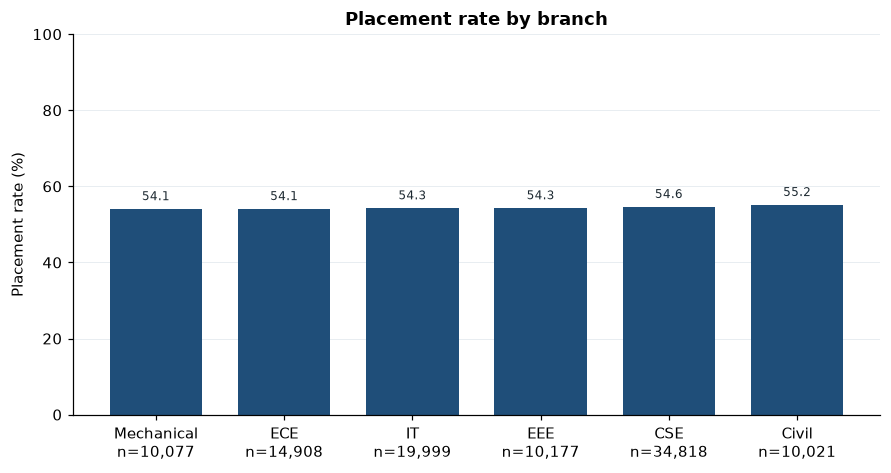

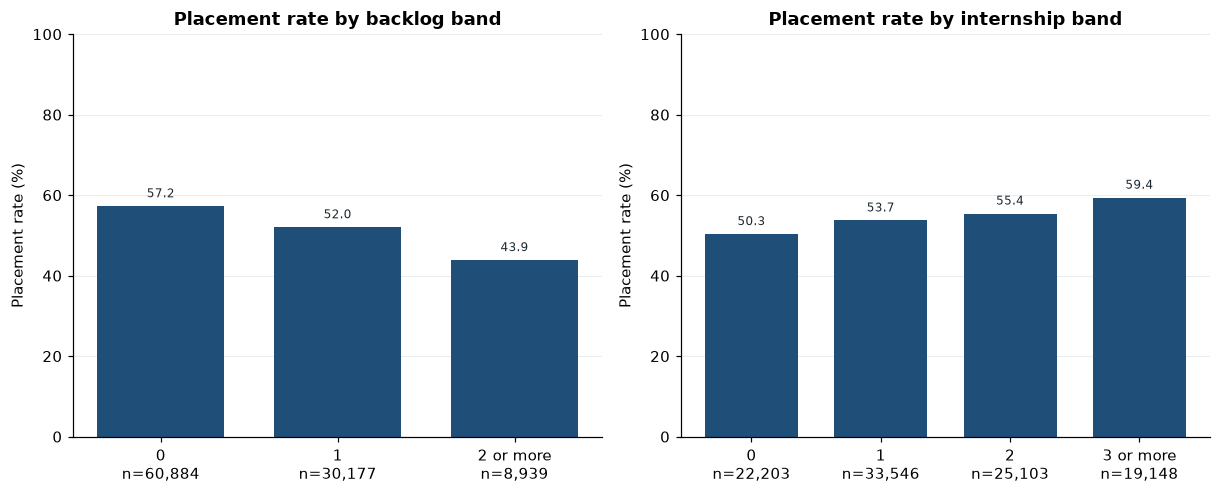

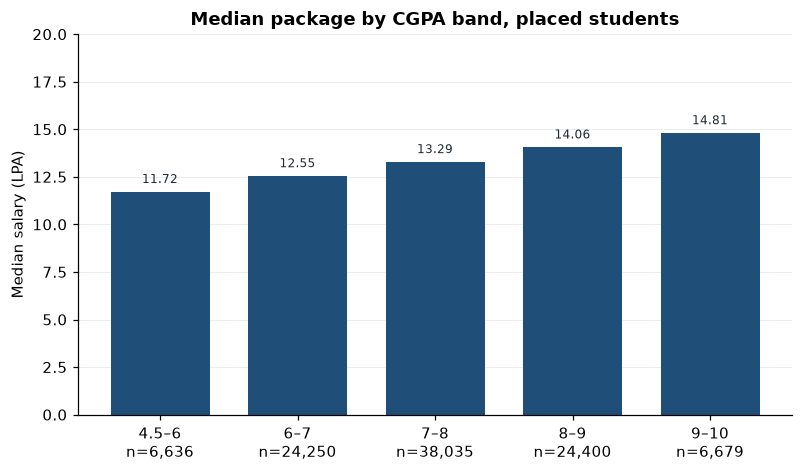

In [6]:
def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E6ECF0", linewidth=0.6)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)


def labelled_bars(ax, labels, values, counts, title, ylabel, ylim, text_at):
    x_pos = np.arange(len(labels))
    ax.bar(x_pos, values, color=BLUE, width=0.72)
    ax.set_xticks(x_pos, [f"{label}\nn={count:,}" for label, count in zip(labels, counts)])
    ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    for x_value, y_value, label_text in zip(x_pos, values, text_at):
        ax.text(x_value, y_value + 0.015 * (ylim[1] - ylim[0]), label_text, ha="center", va="bottom", fontsize=8, color=INK)
    style_axis(ax)


fig, ax = plt.subplots(figsize=(8.2, 4.4))
rates_pct = branch["placement_rate"].to_numpy() * 100
labelled_bars(
    ax,
    branch["branch"].tolist(),
    rates_pct,
    branch["students"].astype(int).tolist(),
    "Placement rate by branch",
    "Placement rate (%)",
    (0, 100),
    [f"{value:.1f}" for value in rates_pct],
)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6))
for ax, table, title in (
    (axes[0], backlog_kpi, "Placement rate by backlog band"),
    (axes[1], internship_kpi, "Placement rate by internship band"),
):
    values = table["placement_rate"].to_numpy() * 100
    labelled_bars(
        ax,
        table["band"].tolist(),
        values,
        table["students"].astype(int).tolist(),
        title,
        "Placement rate (%)",
        (0, 100),
        [f"{value:.1f}" for value in values],
    )
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 4.4))
salaries = cgpa_kpi["median_salary_lpa"].to_numpy()
labelled_bars(
    ax,
    cgpa_kpi["band"].tolist(),
    salaries,
    cgpa_kpi["students"].astype(int).tolist(),
    "Median package by CGPA band, placed students",
    "Median salary (LPA)",
    (0, 20),
    [f"{value:.2f}" for value in salaries],
)
fig.tight_layout()
plt.show()


### What the charts are for

They repeat the tables in a form that is faster to brief. The branch bars sit in a narrow band around the mid-50s because the axis runs from 0 to 100. The backlog bars step down, and the CGPA bars step up. A reader who only has time for the pictures should come away with the same three points as the tables: branch is a small gap, backlogs move the rate, and CGPA moves the package.


## 6. Check which fields move with the package, and stop there

The band tables already separate the rate question from the pay question. This last check asks which numeric fields move in a straight line with the package, among placed students only. It is a Pearson correlation, unadjusted for anything else. It is not a test battery and it is not a model. A model would need a sampling story this file does not have, and it would have to beat a much simpler statement: three fields track pay, and the rest do not.


In [7]:
placed = analysis.loc[analysis["placement_status"].eq("Placed"), analysis.select_dtypes(include="number").columns]
pay_corr = placed.corr(numeric_only=True)["salary_package_lpa"].drop("salary_package_lpa")
pay_corr = pay_corr.reindex(pay_corr.abs().sort_values(ascending=False).index)
pay_corr_table = pay_corr.rename("pearson_r").reset_index().rename(columns={"index": "field"})
print(f"Placed students in the correlation: {len(placed):,}")
display(pay_corr_table.round(3))


Placed students in the correlation: 54,459


,field,pearson_r
0,cgpa,0.499
1,coding_skill_score,0.455
2,internships_count,0.392
3,backlogs,0.008
4,projects_count,-0.005
5,attendance_percentage,0.004
6,mock_interview_score,-0.004
7,hackathons_participated,-0.004
8,linkedin_connections,0.004
9,extracurricular_score,0.003


### What the correlations show

Among the 54,459 placed students, CGPA has a correlation of 0.499 with the package, coding score 0.455, and internships 0.392. The next largest absolute correlation is 0.008, for backlogs. That matches the band table: backlogs change who is placed and do not change the package in any practical way. The three larger correlations are associations in this file. They are not estimates of what would happen if a student raised a grade or added an internship.


## Findings

The audit passes. There are 100,000 rows, no duplicate keys, no missing values, and no values outside the stated rules. Status and salary agree on every row: 45,541 unplaced students at 0 LPA, and 54,459 placed students with a positive package. No row was deleted. The identifier was removed after the uniqueness check, and the zero salaries were left in place.

Lead with two numbers, each with its count. The placement rate is 54.5% (54,459 of 100,000). Among placed students the median package is 13.30 LPA and the mean is 13.32 LPA. Do not average salary over all 100,000 rows. That average would mix real packages with 45,541 structural zeros.

Branch, on its own, is a weak cut. Rates run from 54.1% to 55.2%, and no branch is more than 0.7 percentage points from the cohort. The branch-by-tier pivot is the cross-check, and it is not quite as flat: EEE Tier 1 is 57.1% placed (2,085 students) and EEE Tier 2 is 52.7% (5,024 students), a 4.4 point gap inside one branch. Show that cell. Do not turn it into a ranking of every branch.

The rate and the package do not move together. No backlogs: 57.2% placed, median 13.29 LPA. Two or more backlogs: 43.9% placed, median 13.35 LPA. Internships move both, from 50.3% and 12.54 LPA with none to 59.4% and 14.29 LPA with three or more. CGPA barely moves the rate (53.3% in the lowest band, 55.8% in the highest) and moves the median package from 11.72 LPA to 14.81 LPA. The correlations agree: 0.499 for CGPA, 0.455 for coding score, 0.392 for internships, and 0.008 for the next field, backlogs.

Use the rate and the median as the two headline lines. Use backlog and internship bands when the question is who is placed, and CGPA when the question is the package. Keep the branch margin and the one wider EEE cell in the same pack, with the counts visible. Do not treat any of these associations as the effect of changing a student's record. The publisher describes the file as synthetic.


## Limitations and next steps

- The publisher describes the records as synthetic. A clean audit shows that the fields agree with each other. It does not show that the rows were collected from a real campus, and it is not a basis for a hiring or pay decision.
- The design is observational. A higher CGPA sits with a higher package in this file. That is not an estimate of what a higher grade would do.
- Every package figure is conditional on being placed. The zeros are real in the file and are not packages.
- The branch-by-tier gap is a description of one cross-tab. It is not adjusted for CGPA, backlogs, or internships.
- Five or more backlogs cover 20 students, and seven or more internships cover 96. The top bands exist so those cells are not read as precise rates of their own.
- There is no employer, role, city, or year. The amounts are in LPA.

If a real extract replaces this file, repeat the status-against-amount check and these same SQL cuts before fitting anything heavier. Decide the slices before looking at which cell is widest.


In [8]:
# Lock the rounded figures quoted above. If a figure moves, update the text in the same edit.
expected = {
    "rows": 100_000,
    "duplicate_rows": 0,
    "duplicate_ids": 0,
    "missing_total": 0,
    "out_of_range_total": 0,
    "unplaced_nonzero_salary": 0,
    "placed_nonpositive_salary": 0,
    "n_placed": 54_459,
    "n_unplaced": 45_541,
    "placement_rate_pct": 54.5,
    "placed_mean_lpa": 13.32,
    "placed_median_lpa": 13.30,
    "branch_low_pct": 54.1,
    "branch_high_pct": 55.2,
    "max_branch_gap_pp": 0.7,
    "backlog0_rate": 57.2,
    "backlog0_median": 13.29,
    "backlog2_rate": 43.9,
    "backlog2_median": 13.35,
    "intern0_rate": 50.3,
    "intern0_median": 12.54,
    "intern3_rate": 59.4,
    "intern3_median": 14.29,
    "cgpa_low_rate": 53.3,
    "cgpa_low_median": 11.72,
    "cgpa_high_rate": 55.8,
    "cgpa_high_median": 14.81,
    "r_cgpa": 0.499,
    "r_coding": 0.455,
    "r_internships": 0.392,
    "r_next": 0.008,
    "next_field": "backlogs",
    "eee_high_pct": 57.1,
    "eee_high_n": 2085,
    "eee_low_pct": 52.7,
    "eee_low_n": 5024,
    "thin_backlogs": 20,
    "thin_internships": 96,
}

def band_value(table, band, column):
    row = table.loc[table["band"].eq(band)].iloc[0]
    return row[column]

actual = {
    "rows": len(raw),
    "duplicate_rows": duplicate_rows,
    "duplicate_ids": duplicate_ids,
    "missing_total": missing_total,
    "out_of_range_total": out_of_range_total,
    "unplaced_nonzero_salary": unplaced_nonzero_salary,
    "placed_nonpositive_salary": placed_nonpositive_salary,
    "n_placed": n_placed,
    "n_unplaced": n_students - n_placed,
    "placement_rate_pct": round(placement_rate * 100, 1),
    "placed_mean_lpa": round(placed_mean, 2),
    "placed_median_lpa": round(placed_median, 2),
    "branch_low_pct": round(float(branch["placement_rate"].min()) * 100, 1),
    "branch_high_pct": round(float(branch["placement_rate"].max()) * 100, 1),
    "max_branch_gap_pp": round(float(branch["pp_vs_cohort"].abs().max()), 1),
    "backlog0_rate": round(float(band_value(backlog_kpi, "0", "placement_rate")) * 100, 1),
    "backlog0_median": round(float(band_value(backlog_kpi, "0", "median_salary_lpa")), 2),
    "backlog2_rate": round(float(band_value(backlog_kpi, "2 or more", "placement_rate")) * 100, 1),
    "backlog2_median": round(float(band_value(backlog_kpi, "2 or more", "median_salary_lpa")), 2),
    "intern0_rate": round(float(band_value(internship_kpi, "0", "placement_rate")) * 100, 1),
    "intern0_median": round(float(band_value(internship_kpi, "0", "median_salary_lpa")), 2),
    "intern3_rate": round(float(band_value(internship_kpi, "3 or more", "placement_rate")) * 100, 1),
    "intern3_median": round(float(band_value(internship_kpi, "3 or more", "median_salary_lpa")), 2),
    "cgpa_low_rate": round(float(band_value(cgpa_kpi, "4.5–6", "placement_rate")) * 100, 1),
    "cgpa_low_median": round(float(band_value(cgpa_kpi, "4.5–6", "median_salary_lpa")), 2),
    "cgpa_high_rate": round(float(band_value(cgpa_kpi, "9–10", "placement_rate")) * 100, 1),
    "cgpa_high_median": round(float(band_value(cgpa_kpi, "9–10", "median_salary_lpa")), 2),
    "r_cgpa": round(float(pay_corr.loc["cgpa"]), 3),
    "r_coding": round(float(pay_corr.loc["coding_skill_score"]), 3),
    "r_internships": round(float(pay_corr.loc["internships_count"]), 3),
    "r_next": round(abs(float(pay_corr.iloc[3])), 3),
    "next_field": pay_corr.index[3],
    "eee_high_pct": round(float(stacked_rates.loc[("EEE", "Tier 1")]) * 100, 1),
    "eee_high_n": int(count_pivot.loc[("EEE", "Tier 1")]),
    "eee_low_pct": round(float(stacked_rates.loc[("EEE", "Tier 2")]) * 100, 1),
    "eee_low_n": int(count_pivot.loc[("EEE", "Tier 2")]),
    "thin_backlogs": thin_backlogs,
    "thin_internships": thin_internships,
}

mismatches = {key: (actual[key], expected[key]) for key in expected if actual[key] != expected[key]}
for key in expected:
    print(f"{key}: {actual[key]}")
if mismatches:
    raise AssertionError(mismatches)
if widest_high != ("EEE", "Tier 1") or widest_low != ("EEE", "Tier 2"):
    raise AssertionError((widest_high, widest_low))


rows: 100000
duplicate_rows: 0
duplicate_ids: 0
missing_total: 0
out_of_range_total: 0
unplaced_nonzero_salary: 0
placed_nonpositive_salary: 0
n_placed: 54459
n_unplaced: 45541
placement_rate_pct: 54.5
placed_mean_lpa: 13.32
placed_median_lpa: 13.3
branch_low_pct: 54.1
branch_high_pct: 55.2
max_branch_gap_pp: 0.7
backlog0_rate: 57.2
backlog0_median: 13.29
backlog2_rate: 43.9
backlog2_median: 13.35
intern0_rate: 50.3
intern0_median: 12.54
intern3_rate: 59.4
intern3_median: 14.29
cgpa_low_rate: 53.3
cgpa_low_median: 11.72
cgpa_high_rate: 55.8
cgpa_high_median: 14.81
r_cgpa: 0.499
r_coding: 0.455
r_internships: 0.392
r_next: 0.008
next_field: backlogs
eee_high_pct: 57.1
eee_high_n: 2085
eee_low_pct: 52.7
eee_low_n: 5024
thin_backlogs: 20
thin_internships: 96
